In [32]:
import numpy as np
import cupy as cp
import gc 
import matplotlib.pyplot as plt

from itertools import combinations

import seaborn as sns 

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

%load_ext autoreload
%autoreload 2

import mylib as ml

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [33]:
N = 16
N_iter = 1000

Gamma_tensor = ml.Dirac_gen_GPU(N)

tetrahedra = np.array(list(combinations(range(N), 4)), dtype = np.int32)
triangles = np.array(list(combinations(range(N), 3)), dtype = np.int32)
links = np.array(list(combinations(range(N), 2)), dtype = np.int32)
    
matrices_2, matrices_3, matrices_4 = ml.build_matrices_GPU(Gamma_tensor, links, triangles, tetrahedra)

## Decomment which interactions you wish to turn off

#matrices_2 *= 0
#matrices_3 *= 0
#matrices_4 *= 0

if matrices_3.any() == 0:
    Gamma_5 = Gamma_tensor[0]
    for i in range(N-1):
        Gamma_5 = Gamma_5@Gamma_tensor[i+1]
    
    diag = cp.diag(Gamma_5)
    
    if cp.allclose(diag.real, 0):
        mask = (diag.imag > 0)
    else:
        mask = (diag.real >0)

    matrices_2 = matrices_2[:, mask, :][:,:,mask]
    matrices_3 = matrices_3[:, mask, :][:,:,mask]
    matrices_4 = matrices_4[:, mask, :][:,:,mask]

r_mean, r_index_mean, r_matrix, r_index_matrix = ml.simp_stat_create_GPU(N_iter, N, matrices_2, matrices_3, matrices_4)
    
    
r_est = np.mean(r_mean)
sigma_est = np.std(r_mean)/np.sqrt(len(r_mean))

r_index_est = np.mean(r_index_mean)
sigma_index_est = np.std(r_index_mean)/np.sqrt(len(r_index_mean))

if 'matrices_2' in locals(): del matrices_2
if 'matrices_3' in locals(): del matrices_3
if 'matrices_4' in locals(): del matrices_4
    
cp.get_default_memory_pool().free_all_blocks()
cp.get_default_pinned_memory_pool().free_all_blocks()

gc.collect()

r = r_matrix.flatten()
r_index = r_index_matrix.flatten()

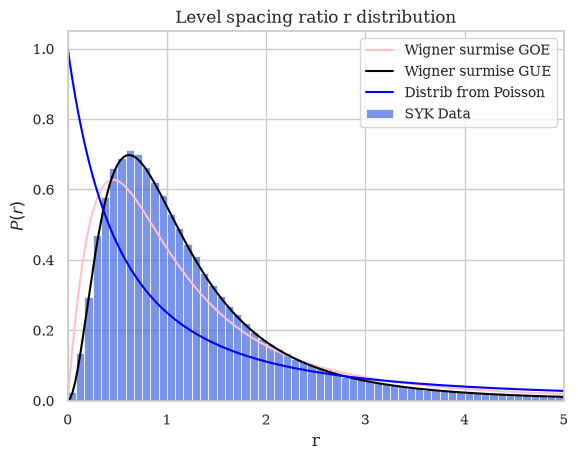

<r> =  1.3665577008138075 ± 0.002526295516164196


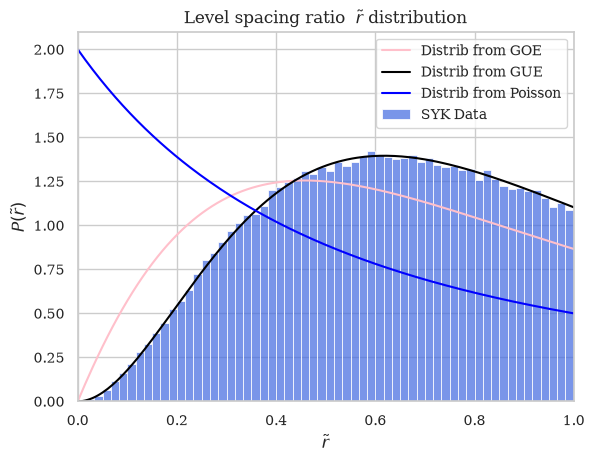

<r_tilde> =  0.6004358962583329 ± 0.0006383554149987682


In [34]:
N_bin = 60

sns.histplot(r, bins=N_bin, binrange=(0,5), stat="density",
            color='royalblue', alpha=0.7, label='SYK Data')

# Comparison curves

r_asse = np.linspace(0, 5, 200)
P_goe = (27/8)*(r_asse + r_asse**2)/(1 + r_asse + r_asse**2)**(2.5)

plt.plot(r_asse, P_goe, color='pink', linewidth=1.5, label='Wigner surmise GOE')

P_gue = (81/4) * (np.sqrt(3)/np.pi) * (r_asse + r_asse**2)**2/(1 + r_asse + r_asse**2)**(4)

plt.plot(r_asse, P_gue, color='black', linewidth=1.5, label='Wigner surmise GUE')


P_poisson = 1/(1+r_asse)**2

plt.plot(r_asse, P_poisson, color='blue', linewidth=1.5, label='Distrib from Poisson')


plt.xlabel(r'r')
plt.ylabel(fr'$P(r)$')
plt.title('Level spacing ratio r distribution')
plt.xlim(0, 5)
plt.legend()
#plt.savefig("SYK_r_distrib.png", dpi=300, bbox_inches='tight')
plt.show()

print(fr"<r> =  {r_est} ± {sigma_est}")


r_index_asse = np.linspace(0, 1, 200)
P_index_goe = (27/4)*(r_index_asse + r_index_asse**2)/(1 + r_index_asse + r_index_asse**2)**(2.5)

plt.plot(r_index_asse, P_index_goe, color='pink', linewidth=1.5, label='Distrib from GOE')

P_index_gue = 2*(81/4) * (np.sqrt(3)/np.pi) * (r_index_asse + r_index_asse**2)**2/(1 + r_index_asse + r_index_asse**2)**(4)

plt.plot(r_index_asse, P_index_gue, color='black', linewidth=1.5, label='Distrib from GUE')

P_index_poisson = 2/(1+r_index_asse)**2

plt.plot(r_index_asse, P_index_poisson, color='blue', linewidth=1.5, label='Distrib from Poisson')


sns.histplot(r_index, bins=N_bin, binrange=(0, 1), stat="density",
            color='royalblue', alpha=0.7, label='SYK Data')

plt.xlabel(fr'$\tilde r$')
plt.ylabel(fr'$P(\tilde r)$')
plt.title(fr'Level spacing ratio  $\tilde r$ distribution')
plt.xlim(0, 1)
plt.legend()
#plt.savefig("SYK_tilde_r_distrib.png", dpi=300, bbox_inches='tight')
plt.show()

print(fr"<r_tilde> =  {r_index_est} ± {sigma_index_est}")